# Paddybird, Layer 1: Data and platform

This notebook builds everything the later layers read from `notebooks/artifacts/layer1/`:

| Step | What | Real or synthetic |
|---|---|---|
| (a) | Labelled flood chips with an **event-level** train/val/test split and a leakage assertion | Real Sen1Floods11 hand-labelled chips (small committed sample); synthetic generator only if the bucket and the cache are both unavailable |
| (b) | STAC search and COG window reads (Sentinel-1 pass dates, a Sentinel-2 window, a Copernicus DEM window) | Real when online; cached JSON/npz otherwise; skipped cleanly when neither |
| (c) | Insurance units (grid units over a study block, pseudo-villages on chips) and a road graph | Units are geometric constructions; roads are real OpenStreetMap (Overpass) when reachable, synthetic lattice otherwise |
| (d) | Receipts that also store survey inclusion probabilities | Mechanism is real; the demo survey runs on train-split chips |
| (e) | Revisit-gap model (days since the last pass, interval-censored submergence) | Real pass dates from STAC when available, simulated schedule otherwise |

Every artifact records its source (`sen1floods11`, `osm-overpass`, `stac`, or `synthetic`) in `MANIFEST.json`, so no later layer can mistake a stand-in for data.

Rules followed (see `notebooks/README.md`): splits by event, fixed seeds, files as the contract, offline re-run from `notebooks/data/` caches. Set `PADDYBIRD_OFFLINE=1` to forbid all network calls.

In [1]:
import json, os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

NB = Path.cwd() if (Path.cwd() / "paddybird").exists() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NB))
from paddybird import data as D, units as U, roads as R, receipts as RC

SEED = 20261118
rng = np.random.default_rng(SEED)
DATA = NB / "data"
OUT = NB / "artifacts" / "layer1"
FIG = OUT / "figures"
for p in (DATA, OUT, FIG, OUT / "receipts"):
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
print("offline mode:", D.offline())
print("numpy", np.__version__, "pandas", pd.__version__, "matplotlib", matplotlib.__version__)

offline mode: True
numpy 2.4.6 pandas 3.1.1 matplotlib 3.11.2


## (a) Labelled flood chips and an event-level split

**Source.** Sen1Floods11 v1.1 hand-labelled chips (Bonafilia et al., 2020; CC BY 4.0), streamed from the public Google Cloud bucket. 446 chips from 11 flood events; each is 512 x 512 Sentinel-1 pixels at 10 m with a hand-drawn water label.

**Working grid.** As in the calibrated threshold instrument (`training/calibration/fit_water.py`): 10 m sigma0 dB, 2 x 2 mean in linear power to 20 m, then +1 dB sigma0-to-gamma0 shift. Label at 20 m is water when at least half of the labelled sub-pixels are water, -1 where nothing is labelled. JRC permanent water from the same chip folder is kept as `perm_water` for layer 2.

**Small committed sample.** Up to 12 chips per event (seeded random choice), centre crop of 128 x 128 at 20 m (2.56 km on a side), float16 backscatter. This keeps `notebooks/data/` and the artifact a few MB. The first run streams about 3 MB per chip; later runs read the cache.

**Fallback.** If the bucket cannot be reached and no cache exists, `D.synthetic_chips` makes a clearly labelled synthetic set with the same layout, and every artifact says `source = synthetic`.

In [2]:
t0 = time.time()
CHIP_CACHE = DATA / "sen1floods11_sample.npz"
chips = D.load_chips(CHIP_CACHE, per_event=12, crop=128, seed=0)
CHIP_SOURCE = str(chips["source"])
print("chip source:", CHIP_SOURCE, "| chips:", len(chips["chip"]), "| shape:", chips["vv"].shape,
      "| took %.1f s" % (time.time() - t0))
if CHIP_SOURCE == "synthetic":
    print("WARNING: SYNTHETIC chips. No mapping metric computed from them is evidence about real floods.")

chip source:

 sen1floods11 | chips: 132 | shape: (132, 128, 128) | took 0.2 s


**Why not the official split.** The Sen1Floods11 train/valid/test files mix chips of the same flood event across splits, so a model can learn an event's local look (sensor geometry, soil, season) and be scored on its neighbours. Paddybird therefore reassigns **whole events**. The assignment was fixed before any model was fit: India (our target domain) and Bolivia (the official held-out region) are **test**; Sri-Lanka (South Asia) and Ghana are **val**; the other seven events are **train**.

In [3]:
lab = chips["label"]
valid = (lab >= 0) & np.isfinite(chips["vv"].astype("float32")) & np.isfinite(chips["vh"].astype("float32"))
chip_df = pd.DataFrame({
    "chip": chips["chip"].astype(str), "event": chips["event"].astype(str),
    "official_split": chips["official_split"].astype(str),
    "valid_share": valid.mean((1, 2)),
    "water_share": np.where(valid.sum((1, 2)) > 0, ((lab == 1) & valid).sum((1, 2)) / np.maximum(valid.sum((1, 2)), 1), np.nan),
    "west": chips["bounds"][:, 0], "south": chips["bounds"][:, 1], "east": chips["bounds"][:, 2], "north": chips["bounds"][:, 3],
})
split_of = D.event_split(chip_df.event, seed=SEED)
chip_df["split"] = chip_df.event.map(split_of)
chip_df["source"] = CHIP_SOURCE

# leakage: how badly the official split mixes events, and proof ours does not
mixed = chip_df.groupby("event").official_split.nunique()
print("events spread over more than one OFFICIAL split:", list(mixed[mixed > 1].index))
D.assert_no_leakage(chip_df, group="event", split="split", ids=("chip",))
print("leakage assertion passed: every event is in exactly one split")
summary = chip_df.groupby(["split", "event"]).agg(chips=("chip", "size"), water_share=("water_share", "mean"),
                                                  valid_share=("valid_share", "mean")).round(3)
summary

events spread over more than one OFFICIAL split: ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']
leakage assertion passed: every event is in exactly one split


chips  water_share  valid_share
split event                                     
test  Bolivia       12        0.140        0.739
      India         12        0.174        0.969
train Mekong        12        0.239        0.953
      Nigeria       12        0.212        0.903
      Pakistan      12        0.056        0.781
      Paraguay      12        0.051        0.917
      Somalia       12        0.046        0.797
      Spain         12        0.060        1.000
      USA           12        0.039        0.929
val   Ghana         12        0.073        0.600
      Sri-Lanka     12        0.150        0.903

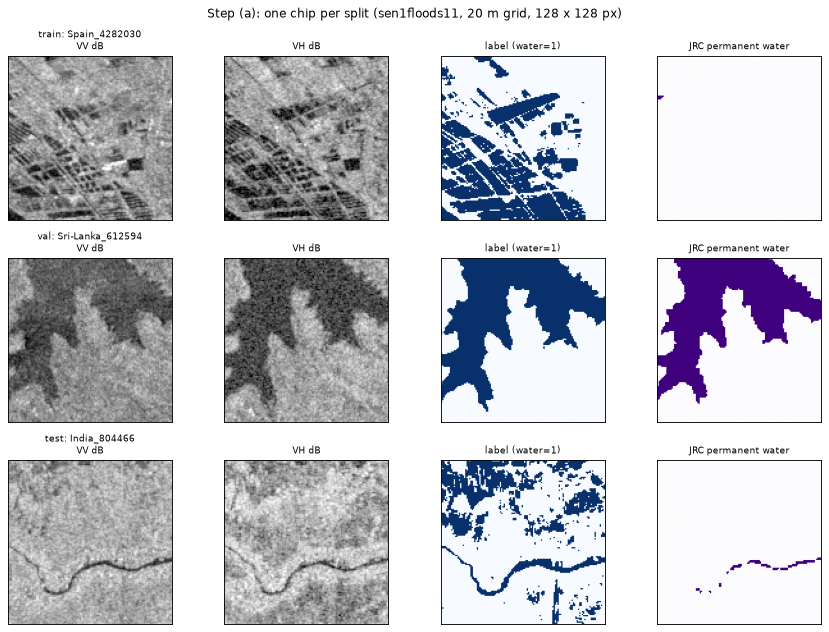

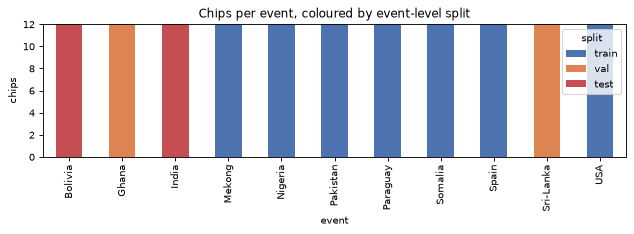

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for row, sp in enumerate(["train", "val", "test"]):
    idx = np.flatnonzero(chip_df.split.values == sp)
    k = idx[np.argmin(np.abs(np.nan_to_num(chip_df.water_share.values[idx], nan=9) - 0.35) + 9 * (chip_df.valid_share.values[idx] < 0.8))]
    vv, vh, lb, pw = (chips[a][k].astype("float32") for a in ("vv", "vh", "label", "perm_water"))
    for col, (img, title, kw) in enumerate([(vv, "VV dB", dict(cmap="gray", vmin=-25, vmax=0)),
                                            (vh, "VH dB", dict(cmap="gray", vmin=-32, vmax=-8)),
                                            (np.ma.masked_less(lb, 0), "label (water=1)", dict(cmap="Blues", vmin=0, vmax=1)),
                                            (np.ma.masked_less(pw, 0), "JRC permanent water", dict(cmap="Purples", vmin=0, vmax=1))]):
        axes[row, col].imshow(img, **kw); axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        axes[row, col].set_title(f"{sp}: {chip_df.chip[k]}\n{title}" if col == 0 else title, fontsize=8)
fig.suptitle(f"Step (a): one chip per split ({CHIP_SOURCE}, 20 m grid, 128 x 128 px)")
fig.tight_layout(); fig.savefig(FIG / "a_chips.png"); plt.show()

ax = chip_df.groupby(["event", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]].plot.bar(
    stacked=True, figsize=(8, 3), color=["#4c72b0", "#dd8452", "#c44e52"])
ax.set_ylabel("chips"); ax.set_title("Chips per event, coloured by event-level split")
plt.tight_layout(); plt.savefig(FIG / "a_split.png"); plt.show()

## (b) STAC search and COG window reads (guarded, optional, offline-safe)

**Study block.** A 12 x 13 km block of the Godavari delta around Amalapuram (Konaseema, Andhra Pradesh): continuous paddy, dense village roads, and flooded in the July 2022 Godavari flood. The block is only a demonstration surface for units, roads and revisit gaps; it has **no ground truth** and no accuracy claim is made on it.

**What runs.**
1. Sentinel-1 search for the 2022 kharif season on Earth Search (search only, its S1 assets are requester-pays) with failover to Planetary Computer. This gives the pass dates for step (e).
2. Sentinel-2 L2A search for a clear dry-season scene on Earth Search (public COGs), then a **window read** of the NIR band and the scene classification over a 2 km box: only the overlapping internal COG blocks are fetched with HTTP range requests.
3. A window read of the Copernicus GLO-30 DEM (public COG) over the same block, for the terrain mask (slope; HAND lives in layer 2).

Search results and the small windows are cached in `notebooks/data/`, so a re-run is offline. Any failure is reported and the step is skipped; nothing downstream depends on (b) except the revisit dates, which fall back to a simulated schedule.

In [5]:
REGION = {"name": "Godavari delta block (Amalapuram, Konaseema, Andhra Pradesh)",
          "bbox": [81.95, 16.52, 82.07, 16.64], "town": {"name": "Amalapuram", "lon": 82.006, "lat": 16.578},
          "season": ["2022-06-01", "2022-10-31"], "note": "demonstration surface; no ground truth"}
BBOX = tuple(REGION["bbox"])
STAC_CACHE = DATA / "stac_cache"
centre = ((BBOX[0] + BBOX[2]) / 2, (BBOX[1] + BBOX[3]) / 2)
small = (centre[0] - 0.009, centre[1] - 0.009, centre[0] + 0.009, centre[1] + 0.009)   # about 2 x 2 km

stac = {"s1": None, "s2": None}
for key, kw in {"s1": dict(sensor="S1", start=REGION["season"][0], end=REGION["season"][1]),
                "s2": dict(sensor="S2", start="2023-01-01", end="2023-03-31", max_cloud=5.0)}.items():
    try:
        stac[key] = D.stac_search(bbox=BBOX, cache_dir=STAC_CACHE, **kw)
        r = stac[key]
        print(f"{key}: {len(r['scenes'])} scenes, from_cache={r['from_cache']}, log={r['log']}")
    except Exception as exc:
        print(f"{key}: STAC unavailable ({type(exc).__name__}: {str(exc)[:120]}); step skipped")

s1: 14 scenes, from_cache=True, log=[{'endpoint': 'earth-search', 'ok': True, 'items': 14}]
s2: 16 scenes, from_cache=True, log=[{'endpoint': 'earth-search', 'ok': True, 'items': 16}]


In [6]:
COG_CACHE = DATA / "cog_cache" / "windows.npz"
windows, win_meta = {}, []
if COG_CACHE.exists():
    z = np.load(COG_CACHE, allow_pickle=False)
    windows = {k: z[k] for k in z.files if k != "meta"}
    win_meta = json.loads(str(z["meta"]))
    print("COG windows from cache:", list(windows))
elif not D.offline():
    try:
        s2 = sorted([s for s in stac["s2"]["scenes"] if s["readable"] and "nir" in s["assets"]],
                    key=lambda s: (s["cloud_cover"], s["date"]))[0]
        for band in ("nir", "scl"):
            t0 = time.time()
            w = D.read_window(D.sign_href(s2["assets"][band], s2.get("signing"), s2["collection"]), small)
            windows[f"s2_{band}"] = w["data"]
            win_meta.append({"name": f"s2_{band}", "scene": s2["id"], "date": s2["date"], "href": w["href"],
                             "crs": w["crs"], "bounds": w["bounds"], "res_m": w["res"], "window": w["window"],
                             "seconds": round(time.time() - t0, 1)})
        t0 = time.time()
        w = D.read_window(D.dem_tile_url(*centre), BBOX)
        windows["dem"] = w["data"]
        win_meta.append({"name": "dem", "scene": "Copernicus GLO-30", "date": None, "href": w["href"], "crs": w["crs"],
                         "bounds": w["bounds"], "res_m": w["res"], "window": w["window"], "seconds": round(time.time() - t0, 1)})
        COG_CACHE.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(COG_CACHE, meta=np.array(json.dumps(win_meta)), **windows)
    except Exception as exc:
        print(f"COG read skipped ({type(exc).__name__}: {str(exc)[:160]})")
for m in win_meta:
    print(f"{m['name']}: window {m['window']} (col, row, w, h) of {m['href'].split('/')[-1]}, pixel {m['res_m']:.6g} in {m['crs']} units")

COG windows from cache: ['s2_nir', 's2_scl', 'dem']
s2_nir: window [10680, 6565, 193, 200] (col, row, w, h) of B08.tif, pixel 10 in EPSG:32644 units
s2_scl: window [5340, 3282, 97, 100] (col, row, w, h) of SCL.tif, pixel 20 in EPSG:32644 units
dem: window [-180, 1296, 432, 432] (col, row, w, h) of Copernicus_DSM_COG_10_N16_00_E082_00_DEM.tif, pixel 0.000277778 in EPSG:4326 units


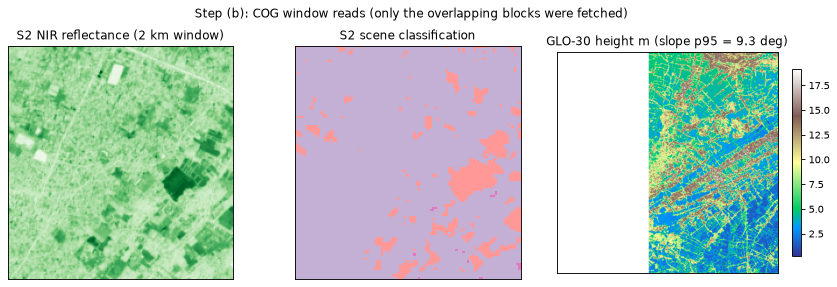

In [7]:
if windows:
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.6))
    if "s2_nir" in windows:
        ax[0].imshow(windows["s2_nir"] * 1e-4, cmap="Greens", vmin=0, vmax=0.5); ax[0].set_title("S2 NIR reflectance (2 km window)")
    if "s2_scl" in windows:
        ax[1].imshow(windows["s2_scl"], cmap="tab20", vmin=0, vmax=11, interpolation="nearest"); ax[1].set_title("S2 scene classification")
    if "dem" in windows:
        dem = windows["dem"]
        gy, gx = np.gradient(dem, 30.0)
        slope = np.degrees(np.arctan(np.hypot(gx, gy)))
        im = ax[2].imshow(dem, cmap="terrain"); plt.colorbar(im, ax=ax[2], shrink=0.8)
        ax[2].set_title(f"GLO-30 height m (slope p95 = {np.nanpercentile(slope, 95):.1f} deg)")
    for a in ax: a.set_xticks([]); a.set_yticks([])
    fig.suptitle("Step (b): COG window reads (only the overlapping blocks were fetched)")
    fig.tight_layout(); fig.savefig(FIG / "b_cog.png"); plt.show()
else:
    print("no COG windows (offline without cache); figure skipped")

## (c) Insurance units and the road graph

**Units.** Crop insurance (PMFBY) settles flood losses per insurance unit, usually a village or gram panchayat. Village polygons for this block are not openly licensed in a form we can commit, so we use two documented stand-ins and keep a loader for public admin polygons (`U.load_admin_geojson`, for example a geoBoundaries or state GIS GeoJSON):

* **Grid units** over the study block: 6 x 6 cells of about 2.1 x 2.2 km (about 470 ha, the size of a delta village). Used by layers 4 and 5 for routing and the unit-calls table.
* **Chip units (pseudo-villages)** on the labelled chips: each 128 x 128 chip is cut into 2 x 2 units of 64 x 64 px (1.28 km, 164 ha). A unit inherits its chip's event and split, so the labelled truth `label_water_share` can be used by layer 3 to score unit calls **without crossing the event split**.

**Roads.** OpenStreetMap drivable ways for the block from the Overpass API (the same query osmnx issues; osmnx is not required), simplified to intersections, largest connected component kept. Dry travel time `base_min` uses assumed rural speeds per road class. If OSM cannot be reached and no cached extract exists, a synthetic jittered lattice is used and marked `synthetic`. Every unit is snapped to its nearest road node; the depot is the node nearest Amalapuram town.

In [8]:
grid = pd.DataFrame(U.grid_units(BBOX, nx=6, ny=6, prefix="G"))
cu = pd.DataFrame(U.chip_units(chip_df.chip, chip_df.event, chip_df.split, chips["bounds"],
                               chip_px=chips["vv"].shape[1], unit_px=chips["vv"].shape[1] // 2))
# per-unit labelled truth and valid share, from the chip arrays
ci = {c: i for i, c in enumerate(chip_df.chip)}
ws, vs = [], []
for r in cu.itertuples():
    l = lab[ci[r.chip], r.r0:r.r1, r.c0:r.c1]; v = valid[ci[r.chip], r.r0:r.r1, r.c0:r.c1]
    vs.append(v.mean()); ws.append(((l == 1) & v).sum() / v.sum() if v.sum() else np.nan)
cu["valid_share"], cu["label_water_share"], cu["source"] = vs, ws, CHIP_SOURCE
D.assert_no_leakage(cu, group="event", split="split", ids=("unit_id",))
assert (cu.groupby("chip").split.nunique() == 1).all()
print(f"grid units: {len(grid)} (mean {grid.area_ha.mean():.0f} ha) | chip units: {len(cu)} "
      f"({cu.area_ha.iloc[0]:.0f} ha each) by split: {cu.split.value_counts().to_dict()}")

grid units: 36 (mean 472 ha) | chip units: 528 (164 ha each) by split: {'train': 336, 'test': 96, 'val': 96}


In [9]:
t0 = time.time()
nodes, edges, ROAD_SOURCE = R.load_road_graph(BBOX, DATA / "osm_godavari_block.json", seed=SEED,
                                              allow_network=not D.offline())
nodes_df, edges_df = pd.DataFrame(nodes), pd.DataFrame(edges)
print(f"road source: {ROAD_SOURCE} | nodes {len(nodes_df)} | edges {len(edges_df)} | "
      f"{edges_df.length_km.sum():.0f} km | took {time.time() - t0:.1f} s")
print(edges_df.groupby("highway").length_km.sum().round(1).sort_values(ascending=False).to_dict())

gi, gd = R.nearest_node(nodes, grid.lon.values, grid.lat.values, BBOX)
grid["node_id"], grid["node_dist_km"] = gi, gd
depot = int(R.nearest_node(nodes, np.array([REGION["town"]["lon"]]), np.array([REGION["town"]["lat"]]), BBOX)[0][0])
tt = R.travel_minutes(len(nodes), edges, [depot])[0]
grid["depot_min_dry"] = tt[grid.node_id.values]
assert np.isfinite(grid.depot_min_dry).all(), "a unit is not reachable from the depot"
print(f"depot node {depot}; dry minutes depot -> unit: median {grid.depot_min_dry.median():.1f}, max {grid.depot_min_dry.max():.1f}")
print(f"unit-to-node snap distance: max {grid.node_dist_km.max():.2f} km")

road source: osm-overpass | nodes 2096 | edges 2567 | 475 km | took 6.0 s
{'residential': 241.9, 'secondary': 76.9, 'primary': 49.0, 'tertiary': 43.3, 'trunk': 34.2, 'unclassified': 15.7, 'track': 10.5, 'living_street': 2.6, 'service': 0.6}
depot node 181; dry minutes depot -> unit: median 9.6, max 16.8
unit-to-node snap distance: max 1.61 km


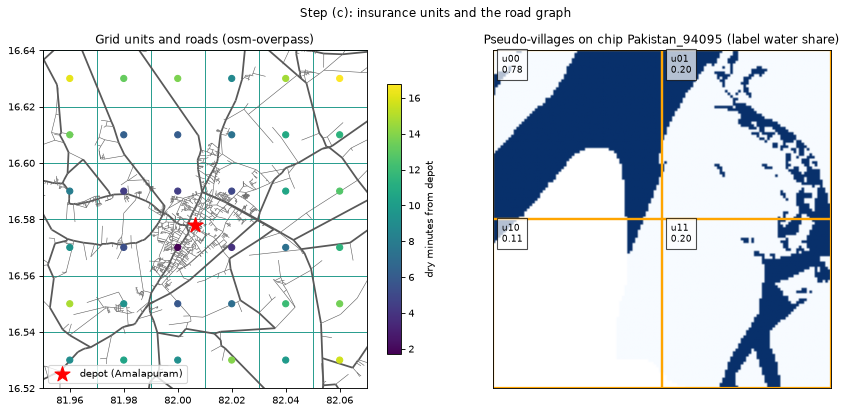

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
xy = nodes_df[["lon", "lat"]].values
segs = np.stack([xy[edges_df.u.values], xy[edges_df.v.values]], 1)
from matplotlib.collections import LineCollection
lw = edges_df.highway.map(lambda h: 1.6 if h.startswith(("primary", "secondary", "trunk")) else 0.5).values
ax[0].add_collection(LineCollection(segs, colors="0.35", linewidths=lw))
for r in grid.itertuples():
    ax[0].add_patch(plt.Rectangle((r.west, r.south), r.east - r.west, r.north - r.south, fill=False, ec="#2a9d8f", lw=0.8))
sc = ax[0].scatter(grid.lon, grid.lat, c=grid.depot_min_dry, cmap="viridis", s=30, zorder=3)
ax[0].scatter(*xy[depot], marker="*", s=200, c="red", zorder=4, label="depot (Amalapuram)")
plt.colorbar(sc, ax=ax[0], shrink=0.8, label="dry minutes from depot")
ax[0].set_title(f"Grid units and roads ({ROAD_SOURCE})"); ax[0].legend(loc="lower left"); ax[0].set_aspect(1 / np.cos(np.radians(16.58)))
ax[0].set_xlim(BBOX[0], BBOX[2]); ax[0].set_ylim(BBOX[1], BBOX[3])
k = ci[chip_df.chip[np.argmin(np.abs(np.nan_to_num(chip_df.water_share.values, nan=9) - 0.35) + 9 * (chip_df.split.values != "train"))]]
ax[1].imshow(np.ma.masked_less(lab[k], 0), cmap="Blues", vmin=0, vmax=1)
h = chips["vv"].shape[1] // 2
for r in cu[cu.chip == chip_df.chip[k]].itertuples():
    ax[1].add_patch(plt.Rectangle((r.c0 - 0.5, r.r0 - 0.5), h, h, fill=False, ec="orange", lw=2))
    ax[1].text(r.c0 + 3, r.r0 + 8, f"{r.unit_id.split('_')[-1]}\n{r.label_water_share:.2f}", color="k", fontsize=8,
               bbox=dict(fc="w", alpha=0.7))
ax[1].set_title(f"Pseudo-villages on chip {chip_df.chip[k]} (label water share)"); ax[1].set_xticks([]); ax[1].set_yticks([])
fig.suptitle("Step (c): insurance units and the road graph"); fig.tight_layout(); fig.savefig(FIG / "c_units_roads.png"); plt.show()

## (d) Receipts that also store survey inclusion probabilities

A receipt is canonical JSON with the SHA-256 of every input and output, the parameters, the scenes and COG windows used, and now a **`survey` block**: for every selected field check, its first-order inclusion probability `pi`, the weight `1 / pi`, its stratum, the design and seed, whether it was actually reached, and (optionally) a corrected realised probability. Layer 3 weights checks by `1 / pi` (Horvitz-Thompson), which removes the bias that routing would otherwise add; layer 4 writes this block for real field days.

**Demo (train split only).** Frame: 16 candidate check points per train-split chip unit (a 4 x 4 lattice of pixels). Strata: unit x map-proxy (VV below -15 dB is "map wet", a fixed physical threshold, nothing is fitted). Design: stratified SRSWOR, 2 checks per stratum, so `pi = n_h / N_h` is known exactly. We check that the Horvitz-Thompson estimate of the frame's wet share is close to the full-frame truth, that `pi` lies in (0, 1], and that the receipt verifies.

In [11]:
tr = cu[cu.split == "train"].reset_index(drop=True)
off = np.linspace(4, chips["vv"].shape[1] // 2 - 5, 4).astype(int)
frame = []
for r in tr.itertuples():
    k = ci[r.chip]
    for a in off:
        for b in off:
            yy, xx = r.r0 + a, r.c0 + b
            if not valid[k, yy, xx]:
                continue
            wet_map = float(chips["vv"][k, yy, xx]) < -15.0
            frame.append({"check_id": f"{r.unit_id}_p{a:02d}{b:02d}", "unit_id": r.unit_id,
                          "stratum": f"{r.unit_id}|{'map_wet' if wet_map else 'map_dry'}", "y": int(lab[k, yy, xx] == 1)})
design = RC.stratified_srswor(frame, n_per_stratum={s: 2 for s in {f["stratum"] for f in frame}}, seed=SEED)
sel = [d for d in design if d["selected"]]
truth = np.mean([f["y"] for f in frame])
ht = RC.ht_total([d["y"] for d in sel], [d["pi"] for d in sel]) / len(frame)
naive = np.mean([d["y"] for d in sel])
print(f"frame {len(frame)} points in {tr.shape[0]} train units | selected {len(sel)} | "
      f"truth {truth:.4f} | HT {ht:.4f} | unweighted {naive:.4f}")
survey = RC.survey_block(design, design="stratified_srswor", seed=SEED)
rec_survey = RC.build_receipt("layer1.survey_demo", inputs={"chips": RC.file_sha256(CHIP_CACHE) if CHIP_CACHE.exists() else RC.digest(chip_df.chip.tolist())},
                              params={"frame": "4x4 lattice per train chip unit", "proxy": "VV < -15 dB", "n_per_stratum": 2},
                              outputs={"ht_wet_share": RC.digest(round(ht, 10))}, survey=survey,
                              notes="Demonstration on train-split chips; inclusion probabilities are exact for this design.")
(OUT / "receipts" / "survey_demo.json").write_text(json.dumps(rec_survey, indent=1))
assert RC.verify_receipt(rec_survey)
print("receipt", rec_survey["receipt_id"], "verifies; first check:", rec_survey["survey"]["checks"][0])

frame 4817 points in 336 train units | selected 844 | truth 0.1046 | HT 0.1163 | unweighted 0.1789
receipt 02149d829b8b88f9 verifies; first check: {'check_id': 'Mekong_1111068_u00_p0422', 'unit_id': 'Mekong_1111068_u00', 'stratum': 'Mekong_1111068_u00|map_dry', 'pi': 0.125, 'weight': 8.0, 'reached': None, 'pi_realised': None}


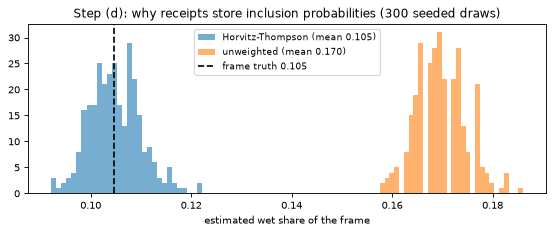

|bias| HT 0.0003 vs unweighted 0.0650


In [12]:
# repeat the draw many times: HT is unbiased for the frame share, the unweighted mean is not
hts, naives = [], []
for s in range(300):
    dd = [d for d in RC.stratified_srswor(frame, {k: 2 for k in {f["stratum"] for f in frame}}, seed=s) if d["selected"]]
    hts.append(RC.ht_total([d["y"] for d in dd], [d["pi"] for d in dd]) / len(frame)); naives.append(np.mean([d["y"] for d in dd]))
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(hts, 30, alpha=0.6, label=f"Horvitz-Thompson (mean {np.mean(hts):.3f})")
ax.hist(naives, 30, alpha=0.6, label=f"unweighted (mean {np.mean(naives):.3f})")
ax.axvline(truth, c="k", ls="--", label=f"frame truth {truth:.3f}")
ax.set_xlabel("estimated wet share of the frame"); ax.legend(fontsize=8)
ax.set_title("Step (d): why receipts store inclusion probabilities (300 seeded draws)")
plt.tight_layout(); plt.savefig(FIG / "d_inclusion.png"); plt.show()
HT_BIAS = abs(np.mean(hts) - truth); NAIVE_BIAS = abs(np.mean(naives) - truth)
print(f"|bias| HT {HT_BIAS:.4f} vs unweighted {NAIVE_BIAS:.4f}")

## (e) Revisit-gap model

A flooded paddy field is only seen on Sentinel-1 pass days. Between passes we do not know its state, so submergence duration is **interval-censored**: onset lies between the last dry pass and the first wet pass, and recession between the last wet pass and the next dry one. Layer 2 turns these brackets into P(submerged >= d days).

Here we build, for each grid unit, the list of Sentinel-1 passes whose footprint covers the unit (one row per date and relative orbit), the gap distribution P(gap >= d), and the days-since-last-pass curve over the 2022 kharif season (Sentinel-1A only after the Sentinel-1B failure of December 2021, so 12-day repeats per orbit). If no STAC result is available, a simulated 12-day schedule is used and marked `synthetic`.

The wet/dry sequence at the end is **illustrative only** (made up to show the censoring logic), not an observation.

In [13]:
passes = []
if stac["s1"] and stac["s1"]["scenes"]:
    REVISIT_SOURCE = "stac:" + stac["s1"]["log"][-1]["endpoint"]
    for g in grid.itertuples():
        for p in D.unique_pass_dates(stac["s1"]["scenes"], point=(g.lon, g.lat)):
            passes.append({"unit_id": g.unit_id, **p, "source": REVISIT_SOURCE})
else:
    REVISIT_SOURCE = "synthetic"
    for g in grid.itertuples():
        for d in D.simulate_passes(*REGION["season"], revisit_days=12, offsets=(0, 5), seed=SEED):
            passes.append({"unit_id": g.unit_id, "date": d, "platform": "simulated", "orbit_state": None,
                           "relative_orbit": None, "scene_id": None, "source": "synthetic"})
passes_df = pd.DataFrame(passes)
per_unit = passes_df.groupby("unit_id").date.apply(lambda s: D.gaps_days(s.tolist()))
all_gaps = np.concatenate(per_unit.values)
surv = D.gap_survival(all_gaps, 40)
rows = []
for u, g in per_unit.items():
    ds = passes_df.loc[passes_df.unit_id == u, "date"]
    rows.append({"unit_id": u, "n_passes": ds.nunique(), "gap_median_days": float(np.median(g)) if len(g) else np.nan,
                 "gap_max_days": int(g.max()) if len(g) else -1})
gap_df = pd.DataFrame(rows)
grid = grid.merge(gap_df, on="unit_id", how="left")
print(f"revisit source: {REVISIT_SOURCE} | passes per unit: {gap_df.n_passes.min()} to {gap_df.n_passes.max()} | "
      f"gap median {np.median(all_gaps):.0f} d, max {all_gaps.max()} d | P(gap >= 12 d) = {surv[12]:.2f}")
print(passes_df.groupby(["orbit_state", "relative_orbit"], dropna=False).date.nunique().rename("dates").to_dict())

revisit source: stac:earth-search | passes per unit: 14 to 14 | gap median 12 d, max 12 d | P(gap >= 12 d) = 0.85
{('ascending', 129): 1, ('descending', 19): 13}


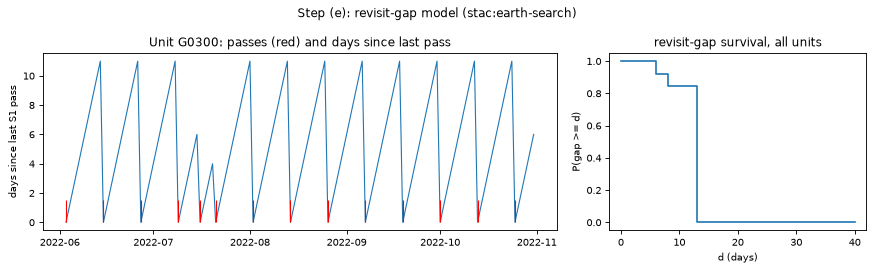

illustrative interval-censored submergence: {'n_passes': 14, 'ever_wet': True, 'days_since_last_wet': 101, 'days_since_last_dry': 0, 'onset_lo': '2022-06-15', 'onset_hi': '2022-06-27', 'recede_lo': '2022-07-16', 'recede_hi': '2022-07-21', 'dur_min': 20, 'dur_max': 35, 'left_censored': False, 'right_censored': False}


In [14]:
u0 = grid.unit_id.iloc[len(grid) // 2]
d0 = sorted(passes_df.loc[passes_df.unit_id == u0, "date"].unique())
since = D.days_since_last_pass(d0, *REGION["season"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw=dict(width_ratios=[2, 1]))
import datetime as dt
days = [dt.date.fromordinal(int(x)) for x in since["day"]]
ax[0].plot(days, since["since_last"], lw=1); ax[0].vlines([dt.date.fromisoformat(d) for d in d0], 0, 1.5, color="r", lw=1)
ax[0].set_ylabel("days since last S1 pass"); ax[0].set_title(f"Unit {u0}: passes (red) and days since last pass")
ax[1].step(range(41), surv, where="post"); ax[1].set_xlabel("d (days)"); ax[1].set_ylabel("P(gap >= d)")
ax[1].set_title("revisit-gap survival, all units")
fig.suptitle(f"Step (e): revisit-gap model ({REVISIT_SOURCE})"); fig.tight_layout(); fig.savefig(FIG / "e_revisit.png"); plt.show()

# ILLUSTRATIVE wet/dry sequence (not observed): dry, dry, wet, wet, wet, dry, ...
demo_wet = [False, False] + [True] * 3 + [False] * (len(d0) - 5)
cen = D.censor_interval(d0, demo_wet)
print("illustrative interval-censored submergence:", cen)
assert cen["dur_min"] <= (cen["dur_max"] or 10**6)

## Write artifacts, receipts and the manifest

All files below are the contract with layers 2 to 5. The schema of each file is listed in `MANIFEST.json` together with its SHA-256, row count or array shapes, and the source flags.

In [15]:
np.savez_compressed(OUT / "chips.npz", chip=chip_df.chip.values.astype("U64"), event=chip_df.event.values.astype("U32"),
                    split=chip_df.split.values.astype("U8"), vv=chips["vv"], vh=chips["vh"], label=chips["label"],
                    perm_water=chips["perm_water"], bounds=chips["bounds"], source=np.array(CHIP_SOURCE))
chip_df.to_parquet(OUT / "chips.parquet", index=False)
cu.to_parquet(OUT / "units_chips.parquet", index=False)
grid.assign(source="grid").to_parquet(OUT / "units_grid.parquet", index=False)
(OUT / "units_grid.geojson").write_text(json.dumps(U.units_to_geojson(grid.drop(columns=[]).to_dict("records")), default=float))
nodes_df.assign(source=ROAD_SOURCE).to_parquet(OUT / "roads_nodes.parquet", index=False)
edges_df.assign(source=ROAD_SOURCE).to_parquet(OUT / "roads_edges.parquet", index=False)
passes_df.to_parquet(OUT / "revisit_passes.parquet", index=False)
(OUT / "revisit_gaps.json").write_text(json.dumps({"source": REVISIT_SOURCE, "season": REGION["season"],
    "gap_days": all_gaps.tolist(), "p_gap_ge_d": [round(float(x), 4) for x in surv],
    "illustrative_censoring_example": cen}, indent=1, default=str))
REGION.update({"depot_node": depot, "road_source": ROAD_SOURCE, "revisit_source": REVISIT_SOURCE})
(OUT / "region.json").write_text(json.dumps(REGION, indent=1))
(OUT / "splits.json").write_text(json.dumps({"by": "event", "events": split_of, "fixed_test": list(D.DEFAULT_TEST_EVENTS),
    "fixed_val": list(D.DEFAULT_VAL_EVENTS), "source": CHIP_SOURCE}, indent=1))
scenes_out = {k: [{kk: s[kk] for kk in ("id", "sensor", "date", "platform", "orbit_state", "relative_orbit", "cloud_cover", "catalog", "bbox")}
                  for s in (v["scenes"] if v else [])] for k, v in stac.items()}
(OUT / "stac_scenes.json").write_text(json.dumps({"windows": win_meta, **scenes_out}, indent=1))
print(sorted(p.name for p in OUT.iterdir()))

['MANIFEST.json', 'chips.npz', 'chips.parquet', 'figures', 'receipts', 'region.json', 'revisit_gaps.json', 'revisit_passes.parquet', 'roads_edges.parquet', 'roads_nodes.parquet', 'splits.json', 'stac_scenes.json', 'units_chips.parquet', 'units_grid.geojson', 'units_grid.parquet']


In [16]:
FILES = {
    "chips.npz": "Chip arrays: vv, vh (float16 gamma0 dB, 20 m), label (int8: 1 water, 0 dry, -1 unlabelled), perm_water (int8 JRC, -1 unknown), chip, event, split, bounds (lon/lat w,s,e,n)",
    "chips.parquet": "One row per chip: chip, event, official_split (not used), split (event-level), valid_share, water_share, bounds, source",
    "units_chips.parquet": "Pseudo-village units on chips: unit_id, chip, event, split, pixel window r0,c0,r1,c1, lon, lat, area_ha, valid_share, label_water_share (truth), source",
    "units_grid.parquet": "Grid units over the study block: unit_id, row, col, lon, lat, west, south, east, north, area_ha, node_id, node_dist_km, depot_min_dry, n_passes, gap_median_days, gap_max_days",
    "units_grid.geojson": "Same grid units as polygons (EPSG:4326)",
    "roads_nodes.parquet": "Road nodes: node_id, osm_id (-1 if synthetic), lon, lat, x_km, y_km (local plane), source",
    "roads_edges.parquet": "Undirected road edges u<v: length_km, highway, speed_kmh, base_min (dry minutes), source",
    "revisit_passes.parquet": "Sentinel-1 passes covering each grid unit: unit_id, date, platform, orbit_state, relative_orbit, scene_id, source",
    "revisit_gaps.json": "Gap days between passes, P(gap >= d) for d=0..40, an illustrative censoring example",
    "region.json": "Study block bbox, depot node, season, sources",
    "splits.json": "Event -> split map (train/val/test)",
    "stac_scenes.json": "STAC scenes found (S1 season, S2 dry season) and COG windows read",
    "receipts/survey_demo.json": "Receipt with a survey block of inclusion probabilities (train split demo)",
    "receipts/layer1_build.json": "Receipt of this layer: input and output hashes, params, scenes, windows",
}
outs = {n: RC.file_sha256(OUT / n) for n in FILES if n != "receipts/layer1_build.json"}
ins = {"chip_cache": RC.file_sha256(CHIP_CACHE) if CHIP_CACHE.exists() else "synthetic"}
osm_cache = DATA / "osm_godavari_block.json"
if osm_cache.exists(): ins["osm_cache"] = RC.file_sha256(osm_cache)
for p in sorted(STAC_CACHE.glob("*.json")) if STAC_CACHE.exists() else []: ins[f"stac/{p.name}"] = RC.file_sha256(p)
build = RC.build_receipt("layer1.build", inputs=ins, params={"seed": SEED, "per_event": 12, "crop_px": int(chips["vv"].shape[1]),
                         "grid_units": [6, 6], "bbox": list(BBOX), "split_test": list(D.DEFAULT_TEST_EVENTS), "split_val": list(D.DEFAULT_VAL_EVENTS)},
                         outputs=outs, scenes=[{k: s[k] for k in ("id", "date", "catalog")} for s in (stac["s1"] or {"scenes": []})["scenes"][:200]],
                         windows=win_meta)
(OUT / "receipts" / "layer1_build.json").write_text(json.dumps(build, indent=1))
assert RC.verify_receipt(build, {n: OUT / n for n in outs})
SOURCES = {"chips": CHIP_SOURCE, "roads": ROAD_SOURCE, "revisit": REVISIT_SOURCE,
           "stac": "live-or-cached" if any(stac.values()) else "unavailable", "units": "grid and chip constructions (no admin polygons)"}
man = RC.write_manifest(OUT, layer=1, seed=SEED, files=FILES, sources=SOURCES, source_hashes=ins,
                        extra={"notebook": "01_data_platform.ipynb", "split": {"by": "event", "events": split_of},
                               "pixel_m": 20.0, "chip_px": int(chips["vv"].shape[1]), "unit_px": int(chips["vv"].shape[1] // 2),
                               "region": REGION, "receipt_id": build["receipt_id"]})
print(man.read_text()[:1500])

{
  "schema": "paddybird.manifest/1",
  "layer": 1,
  "seed": 20261118,
  "created_utc": "2026-11-18T06:09:34+00:00",
  "sources": {
    "chips": "sen1floods11",
    "roads": "osm-overpass",
    "revisit": "stac:earth-search",
    "stac": "live-or-cached",
    "units": "grid and chip constructions (no admin polygons)"
  },
  "source_hashes": {
    "chip_cache": "63ba3feca8f0bf3fcd7788896b554711d12c418bed59b9b807c035a435928ebc",
    "osm_cache": "d48a5da34f8af011819d82d29d659ab9b06631a296564ea82c00f69579861da3",
    "stac/stac_S1_d6a0afd843f4935e.json": "357444dd80633bd4016a2e7bb1c4479c0a1cfeec0d6720da742a546b7013e254",
    "stac/stac_S2_ed7cd71337f2b009.json": "86d5e8ae98c28bab6a0b388a52d149df3502d5685cc70c9837e4e06957b07b1e"
  },
  "files": {
    "chips.npz": {
      "description": "Chip arrays: vv, vh (float16 gamma0 dB, 20 m), label (int8: 1 water, 0 dry, -1 unlabelled), perm_water (int8 JRC, -1 unknown), chip, event, split, bounds (lon/lat w,s,e,n)",
      "bytes": 6607751,
      "

## Final checks

The key "metric" of a data layer is that nothing leaks and everything is reproducible. The bounds checked below:

* event-level split, every split non-empty, chip and unit tables agree on it;
* at least 50 real chips (or the run is flagged synthetic);
* road graph connected and every unit centroid within 2 km of a road node (real OSM: a few delta cells are mostly river or paddy with no mapped road near the centre; layer 4 can add the walk) and reachable from the depot;
* the Horvitz-Thompson bias over 300 draws is under 0.01 and smaller than the unweighted bias, every `pi` in (0, 1], both receipts verify;
* the committed layer 1 artifacts are under 20 MB.

In [17]:
size_mb = sum(p.stat().st_size for p in OUT.rglob("*") if p.is_file()) / 1e6
checks = {
    "event split, no leakage": chip_df.groupby("event").split.nunique().max() == 1 and cu.groupby("event").split.nunique().max() == 1,
    "all three splits non-empty": set(chip_df.split) == {"train", "val", "test"},
    "chips >= 50 real (else synthetic flagged)": (len(chip_df) >= 50 and CHIP_SOURCE == "sen1floods11") or CHIP_SOURCE == "synthetic",
    "road graph reachable from depot": bool(np.isfinite(grid.depot_min_dry).all()),
    "units snapped within 2 km": bool(grid.node_dist_km.max() < 2.0),
    "HT bias < 0.01 and below unweighted": HT_BIAS < 0.01 and HT_BIAS < NAIVE_BIAS,
    "pi in (0, 1]": all(0 < c["pi"] <= 1 for c in rec_survey["survey"]["checks"]),
    "receipts verify": RC.verify_receipt(json.loads((OUT / "receipts" / "survey_demo.json").read_text()))
                        and RC.verify_receipt(json.loads((OUT / "receipts" / "layer1_build.json").read_text())),
    f"artifacts under 20 MB ({size_mb:.1f} MB)": size_mb < 20,
}
for k, v in checks.items(): print(("PASS " if v else "FAIL ") + k)
print("sources:", SOURCES)
assert all(checks.values()), "layer 1 checks failed"

PASS event split, no leakage
PASS all three splits non-empty
PASS chips >= 50 real (else synthetic flagged)
PASS road graph reachable from depot
PASS units snapped within 2 km
PASS HT bias < 0.01 and below unweighted
PASS pi in (0, 1]
PASS receipts verify
PASS artifacts under 20 MB (7.9 MB)
sources: {'chips': 'sen1floods11', 'roads': 'osm-overpass', 'revisit': 'stac:earth-search', 'stac': 'live-or-cached', 'units': 'grid and chip constructions (no admin polygons)'}
